In [3]:
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import box

def aggregate_points(geodf, cell_size, category_column):
    """
    Aggregates points in a GeoDataFrame into a grid and calculates point counts and category distribution.

    Parameters:
        geodf (GeoDataFrame): GeoDataFrame containing point geometries.
        cell_size (float): Size of the square grid cells (in the coordinate system's units).
        category_column (str): Column name for categorical data.

    Returns:
        GeoDataFrame: Grid GeoDataFrame with aggregated point counts and category proportions.
    """
    # Create the bounding box for the grid
    xmin, ymin, xmax, ymax = geodf.total_bounds
    x_bins = np.arange(xmin, xmax + cell_size, cell_size)
    y_bins = np.arange(ymin, ymax + cell_size, cell_size)
    print(' Create the grid cells as polygons')
    # Create the grid cells as polygons
    grid_cells = []
    for x in x_bins[:-1]:
        for y in y_bins[:-1]:
            grid_cells.append(box(x, y, x + cell_size, y + cell_size))
    grid = gpd.GeoDataFrame({"geometry": grid_cells}, crs=geodf.crs)
    print('Spatial join to assign points to grid cell')
    # Spatial join to assign points to grid cells
    joined = gpd.sjoin(geodf, grid, how="left", op="within")
    joined["grid_id"] = joined.index_right
    print("Aggregate points by grid cell")
    # Aggregate points by grid cell
    agg = joined.groupby("grid_id").agg(
        point_count=("geometry", "count"),
        category_distribution=(category_column, lambda x: dict(x.value_counts()))
    ).reset_index()

    # Merge results back to the grid
    grid = grid.reset_index().rename(columns={"index": "grid_id"})
    grid = grid.merge(agg, on="grid_id", how="left")

    # Fill NaN for empty cells
    grid["point_count"] = grid["point_count"].fillna(0).astype(int)
    grid["category_distribution"] = grid["category_distribution"].fillna({})
    
    grid = grid.loc[grid.point_count > 0].reset_index(drop=True)
    grid["most_common_category"] = grid["category_distribution"].apply(
    lambda dist: max(dist, key=dist.get) if dist else None)

    return grid



In [47]:
aggregated_grid = aggregated_grid.drop('grid_id', axis=1)

In [36]:
aggregated_grid['point_count']= aggregated_grid['point_count'].astype('int')

In [40]:
aggregated_grid.columns

Index(['geometry', 'point_count', 'category_distribution',
       'most_common_category'],
      dtype='object')

In [43]:
aggregated_grid[['geometry',
       'most_common_category']].dtypes

geometry                geometry
most_common_category      object
dtype: object

In [50]:
aggregated_grid[['geometry', 
       'most_common_category']].to_file('../data/tmp/isprs_train_dst_grid_6.gpkg')

In [45]:
!pwd

/home/jan/Documents/EPFL/project_2/notebooks


In [56]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

import contextily as ctx 



in_path = "../data/labels/dataset_v5/labels_no_regrowth.csv"
df = pd.read_csv(in_path)
df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
gdf = gpd.GeoDataFrame(df)

# Input parameters
cell_size = 0.75  # Adjust based on your CRS units
category_column = 'driver'


# Assuming you already have a GeoDataFrame named 'geodf'
# Aggregate the points into a grid
aggregated_grid = aggregate_points(gdf, cell_size, category_column)

aggregated_grid.crs = 4326
aggregated_grid = aggregated_grid.to_crs(3857)

 Create the grid cells as polygons
Spatial join to assign points to grid cell
Aggregate points by grid cell


/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [ ]:
# Get the 'tab20' colormap
cmap = plt.get_cmap('tab20')

# Get the list of colors in 'tab20'
colors = [cmap(i) for i in range(cmap.N)]

# Modify the order (example: reverse the order)
modified_colors = colors[::-1]


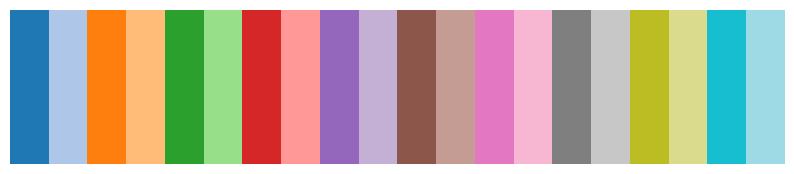

In [71]:
import matplotlib.pyplot as plt

# Get the 'tab20' colormap
cmap = plt.get_cmap('tab20')

# Get the list of colors in 'tab20'
colors = [cmap(i) for i in range(cmap.N)]
# Plot each color as a bar
plt.figure(figsize=(10, 2))  # Adjust the figure size as needed
plt.imshow([colors], aspect='auto')
plt.axis('off')  # Turn off axis
plt.show()

In [99]:

modified_colors = [cmap(i) for i in ]


In [155]:
import matplotlib.colors as colors


In [156]:
hex_colors = [colors.to_hex(cmap(i)) for i in [0,2,4,6,8,10,12,5,16,18, 14]]
green_red = [colors.to_hex(cmap(i)) for i in [5,7]]

In [100]:
# Get unique categories
categories = aggregated_grid['most_common_category'].unique()

# Map colors to the categories
color_map = dict(zip(categories, modified_colors))

# Create a 'color' column in the dataframe
aggregated_grid['color'] = aggregated_grid['most_common_category'].map(color_map)


In [96]:

# Check the number of unique categories
num_categories = len(aggregated_grid['most_common_category'].unique())

# If there are fewer colors than categories, repeat or trim the colors list
modified_colors = modified_colors[:num_categories]  # Trim if too many colors
# or
# modified_colors = modified_colors * (num_categor

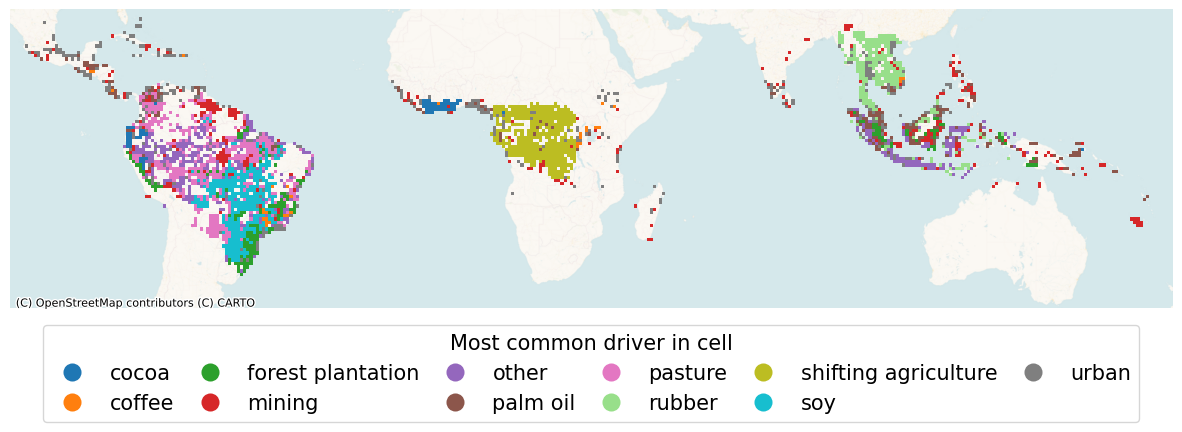

In [180]:


# Plot the grid on a basemap
fig, ax = plt.subplots(figsize=(15, 8))


# Plot the grid with colors by the most common category
aggregated_grid.plot(
    column='most_common_category',
    #color=aggregated_grid['color'],
    #cmap='tab20',  # Use a qualitative colormap
    cmap=colors.ListedColormap(hex_colors),
    #color=modified_colors,
    legend=True,
    ax=ax,
    legend_kwds={
        'loc': 'upper center', 
        'bbox_to_anchor': (0.5, -0.02),  # Position below the plot
        'title': 'Most common driver in cell',
        'ncol': 6,  # Number of columns in the legend
        'fontsize':15,
        'title_fontsize':15, 
        'markerscale':1.3,
        # 'labelspacing':0.5,
        # 'handletextpad':0.5,
        'columnspacing': 0.7
    },
    #edgecolor='k',
    linewidth=0,
)

#Use bbox from the other plot to be consistent
# Calculate the bounding box of the data
#minx, miny, maxx, maxy = aggregated_grid.total_bounds



# Set axis limits to the extent of the data (adjust margins if necessary)
ax.set_xlim(minx - 200000 , maxx + 200000)  # Add small buffer to the bounding box if needed
ax.set_ylim(miny - 200000, maxy + 200000)

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.CartoDB.VoyagerNoLabels, crs=aggregated_grid.crs, zoom=6)

# Title and labels
#ax.set_title("Training dataset distribution", fontsize=12)
#ax.set_xlabel("Longitude", fontsize=12)
#ax.set_ylabel("Latitude", fontsize=12)
# Remove the axes ticks and labels
ax.set_xticks([])  # Remove longitude ticks
ax.set_yticks([])  # Remove latitude ticks
ax.set_xticklabels([])  # Remove longitude labels
ax.set_yticklabels([])  # Remove latitude labels

# Remove the plot borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)



# Save the figure
plt.savefig("../paper/dataset_distribution.png", dpi=300, bbox_inches='tight', transparent=True)

plt.show()

In [77]:
xx = aggregated_grid.most_common_category.unique()

array(['cocoa', 'coffee', 'forest plantation', 'mining', 'other',
       'palm oil', 'pasture', 'rubber', 'shifting agriculture', 'soy',
       'urban'], dtype=object)

In [117]:
grid = gpd.read_file('../data/tmp/grid.gpkg')

In [125]:

grid['split2'] = grid['split'].apply(lambda x: "Train" if x != 4 else "Test")


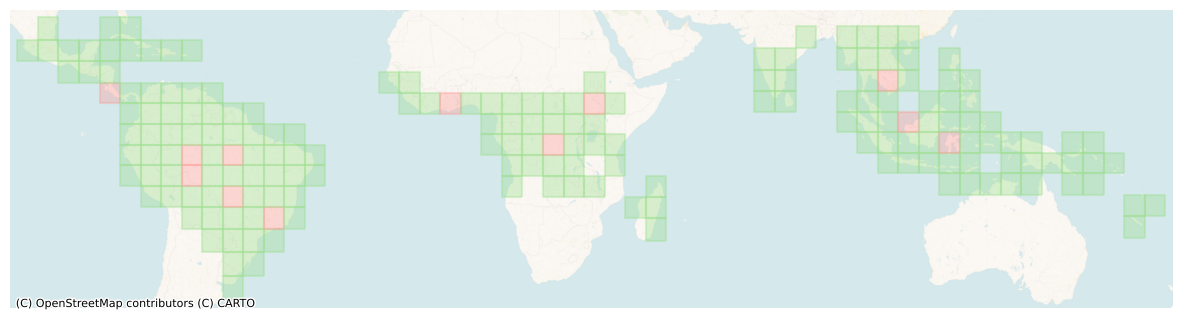

In [171]:


# Plot the grid on a basemap
fig, ax = plt.subplots(figsize=(15, 8))


grid = grid.to_crs(3857)


# Retrieve the color map and assign colors to polygons
grid['color'] = grid['split2'].map({
    "Train": green_red[0],  # First color in colormap
    "Test": green_red[1]    # Second color in colormap
})

# Plot with transparency and matching edge color
grid.plot(
    color=grid['color'],      # Fill color
    edgecolor=grid['color'],  # Border color matches fill color
    alpha=0.35,                # Transparency for fill
    linewidth=1.5,            # Border line width
    ax=ax,                   # Plot on the defined axis
    legend_kwds={
    'loc': 'upper center', 
    'bbox_to_anchor': (0.5, -0.02),  # Position below the plot
    'title': 'Data split',
    'ncol': 2  # Number of columns in the legend
},
    
)



# Calculate the bounding box of the data
minx, miny, maxx, maxy = grid.total_bounds


#Use bbox from the other plot to be consistent
# Set axis limits to the extent of the data (adjust margins if necessary)
ax.set_xlim(minx - 200000 , maxx + 200000)  # Add small buffer to the bounding box if needed
ax.set_ylim(miny - 200000, maxy + 200000)


# Add basemap
ctx.add_basemap(ax, source=ctx.providers.CartoDB.VoyagerNoLabels, crs=aggregated_grid.crs, zoom=6)

# Title and labels
#ax.set_title("Training dataset distribution", fontsize=12)
#ax.set_xlabel("Longitude", fontsize=12)
#ax.set_ylabel("Latitude", fontsize=12)
# Remove the axes ticks and labels
ax.set_xticks([])  # Remove longitude ticks
ax.set_yticks([])  # Remove latitude ticks
ax.set_xticklabels([])  # Remove longitude labels
ax.set_yticklabels([])  # Remove latitude labels

# Remove the plot borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)



# Save the figure
plt.savefig("../paper/dataset_split.png", dpi=300, bbox_inches='tight', transparent=True)

plt.show()

In [165]:
green_red

['#98df8a', '#ff9896']

In [166]:
red_g = [ '#ff9896', '#98df8a',]

In [170]:
grid

,split,geometry,split2,color
0,1,"POLYGON ((18646014.708 -2875744.624, 18646014....",Train,#98df8a
1,3,"POLYGON ((18646014.708 -2273030.927, 18646014....",Train,#98df8a
2,3,"POLYGON ((19202612.162 -2273030.927, 19202612....",Train,#98df8a
3,2,"POLYGON ((13636637.622 -1689200.140, 13636637....",Train,#98df8a
4,2,"POLYGON ((14193235.076 -1689200.140, 14193235....",Train,#98df8a
...,...,...,...,...
180,2,"POLYGON ((-7458405.883 1920825.040, -7458405.8...",Train,#98df8a
181,3,"POLYGON ((-6901808.429 1920825.040, -6901808.4...",Train,#98df8a
182,3,"POLYGON ((-10797990.607 2511525.235, -10797990...",Train,#98df8a
183,0,"POLYGON ((-9128198.245 2511525.235, -9128198.2...",Train,#98df8a
